# Cuaderno 2: Análisis Exploratorio de Datos (EDA), Descomposición de Varianza, Diagnóstico de Multicolinealidad y Dinámica Post-COVID-19

**Proyecto:** Impacto del Gasto Educativo Contratado (SECOP) y del Presupuesto General de la Nación (PGN) sobre la Calidad Educativa Oficial en Colombia (2019–2025).

---

### Propósito del Análisis Exploratorio
Antes de proceder a la modelación econométrica y de aprendizaje estadístico, este cuaderno ejecuta un diagnóstico estadístico y visual exhaustivo sobre los paneles maestros departamental y municipal:
1. **Momentos Distribucionales, Pruebas de Normalidad y Distribuciones Empíricas:** Cálculo de estadísticos de tendencia central, dispersión, asimetría, curtosis, contrastes de normalidad (Shapiro-Wilk y Jarque-Bera) y paneles gráficos de distribuciones.
2. **Descomposición Formal de Varianza (*Between* vs. *Within* vs. *Two-Way Residual*):** Cuantificación de la proporción de variabilidad del puntaje Saber 11 que es permanente entre departamentos ($84\%$) frente a la señal temporal residual (*two-way within*, $\text{DE} = 2,11$ puntos), así como la heterocedasticidad según el tamaño de la matrícula departamental.
3. **Cálculo y Visualización en Vivo de Factores de Inflación de Varianza (*Two-Way Within* VIF):** Verificación matemática de la ortogonalidad entre los componentes de gasto (CAPEX vs. Bienestar) y los controles socioeconómicos tras extraer efectos fijos departamentales y temporales.
4. **Reconstrucción Censal del Choque COVID-19 y la Recuperación Pedagógica (2019–2025):** Demostración empírica del sesgo de selección en 2020 ($-4,10\%$ de evaluados oficiales y $+1,34$ puntos por composición) frente a la caída real del aprendizaje en el retorno presencial de 2021 ($-1,83$ puntos vs. 2019 y $-3,17$ puntos vs. 2020) y su recuperación hacia 2024.
5. **Mapas de Calor de Correlación en Niveles vs. Diferencias ($\Delta Y_{it}$), Gráficos de Dispersión (*Between* vs. *Within*), Distancia Multivariada de Mahalanobis y Sesgo Espacial de Capitales Departamentales.**

### 1. Estadísticos Descriptivos Univariados, Contrastes de Normalidad y Distribuciones Empíricas

Se cargan los paneles maestros de forma portable, se calculan los momentos distribucionales y las pruebas de normalidad (**Shapiro-Wilk** y **Jarque-Bera**), y se renderiza en vivo el panel de distribuciones de las variables principales.

=== Tabla de Estadísticos Descriptivos y Pruebas de Normalidad (Panel Departamental) ===


,Variable,N,Media,DE,P10,P25,Mediana,P75,P90,Asimetría,Curtosis,Shapiro_p,JarqueBera_p
0,punt_global_mean,231,238.645,15.817,214.994,226.131,241.319,250.015,257.393,-0.327,-0.712,0.000,0.011
1,punt_global_p25,231,203.890,15.092,182.000,191.000,206.000,214.500,223.000,-0.222,-0.785,0.000,0.019
2,punt_global_p75,231,269.519,18.820,242.000,256.000,274.000,283.500,292.000,-0.426,-0.567,0.000,0.006
3,gasto_edu_pc_miles,165,"23,402.406","31,399.775","6,846.093","10,078.589","14,034.696","23,634.542","44,089.641",4.437,25.013,0.000,0.000
4,gasto_capex_pc_miles,165,"7,442.200","18,661.643",727.471,"1,360.530","3,148.009","6,104.688","16,469.417",7.676,70.544,0.000,0.000
5,gasto_bienestar_pc_miles,165,"15,960.206","16,624.991","5,441.083","7,638.397","10,872.356","15,053.431","31,412.534",2.841,8.754,0.000,0.000
6,log_gasto_edu_pc,161,16.614,0.771,15.768,16.173,16.498,16.999,17.612,0.925,1.320,0.000,0.000
7,log_gasto_capex_pc,165,7.873,1.797,6.588,7.216,8.055,8.717,9.709,-2.288,9.323,0.000,0.000
8,log_gasto_bienestar_pc,165,9.179,1.608,8.602,8.941,9.294,9.619,10.355,-4.439,23.995,0.000,0.000
9,log_pgn_educacion_pc,231,16.308,0.572,15.659,15.973,16.220,16.561,17.124,0.916,1.604,0.000,0.000


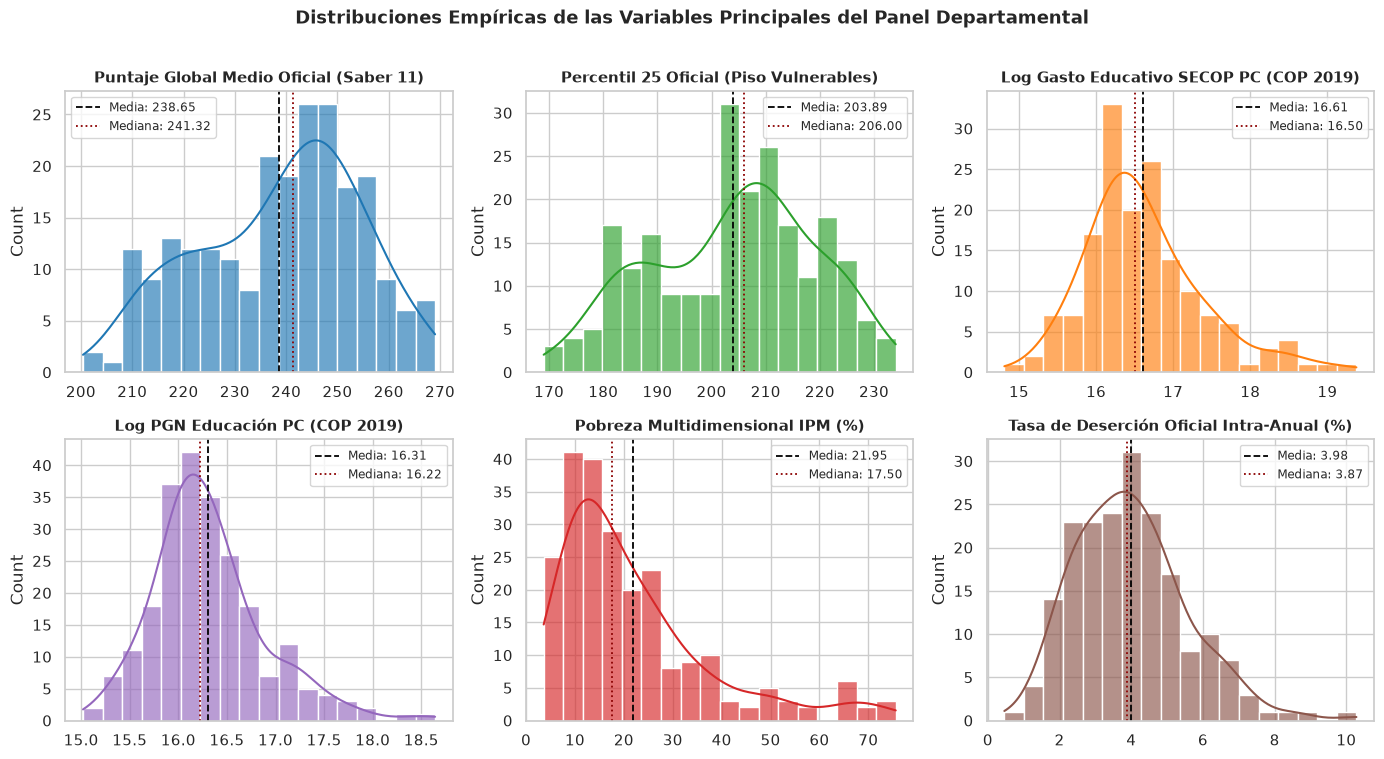

In [1]:
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font='sans-serif')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.3f}'.format)

def resolve_project_root() -> Path:
    """Resuelve de forma portable la raíz del proyecto o del paquete Entregable."""
    cwd = Path.cwd().resolve()
    for candidate in [cwd, cwd.parent, cwd.parent.parent]:
        if (candidate / 'Outputs' / 'dataset_maestro_departamental_v4.parquet').exists():
            return candidate
    return cwd.parent

BASE_DIR = resolve_project_root()
DATA_DIR = BASE_DIR / 'Data'
OUTPUTS_DIR = BASE_DIR / 'Outputs'
TABLAS_DIR = OUTPUTS_DIR / 'Tablas'
FIGURAS_DIR = OUTPUTS_DIR / 'Figuras'

df = pd.read_parquet(OUTPUTS_DIR / 'dataset_maestro_departamental_v4.parquet')
df_mun = pd.read_parquet(OUTPUTS_DIR / 'dataset_maestro_municipal_v4.parquet')

vars_eda = [
    'punt_global_mean', 'punt_global_p25', 'punt_global_p75',
    'gasto_edu_pc_miles', 'gasto_capex_pc_miles', 'gasto_bienestar_pc_miles',
    'log_gasto_edu_pc', 'log_gasto_capex_pc', 'log_gasto_bienestar_pc',
    'log_pgn_educacion_pc', 'ipm_depto', 'cobertura_neta_media', 'tasa_desercion'
]

desc_rows = []
for col in vars_eda:
    s = df[col].dropna()
    sw_stat, sw_p = stats.shapiro(s)
    jb_stat, jb_p = stats.jarque_bera(s)
    desc_rows.append({
        'Variable': col,
        'N': len(s),
        'Media': s.mean(),
        'DE': s.std(),
        'P10': s.quantile(0.10),
        'P25': s.quantile(0.25),
        'Mediana': s.median(),
        'P75': s.quantile(0.75),
        'P90': s.quantile(0.90),
        'Asimetría': s.skew(),
        'Curtosis': s.kurtosis(),
        'Shapiro_p': sw_p,
        'JarqueBera_p': jb_p
    })
df_desc = pd.DataFrame(desc_rows)
print('=== Tabla de Estadísticos Descriptivos y Pruebas de Normalidad (Panel Departamental) ===')
display(df_desc)

# Panel visual en vivo de distribuciones empíricas (6 variables clave)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
plot_cfg = [
    ('punt_global_mean', 'Puntaje Global Medio Oficial (Saber 11)', '#1f77b4'),
    ('punt_global_p25', 'Percentil 25 Oficial (Piso Vulnerables)', '#2ca02c'),
    ('log_gasto_edu_pc', 'Log Gasto Educativo SECOP PC (COP 2019)', '#ff7f0e'),
    ('log_pgn_educacion_pc', 'Log PGN Educación PC (COP 2019)', '#9467bd'),
    ('ipm_depto', 'Pobreza Multidimensional IPM (%)', '#d62728'),
    ('tasa_desercion', 'Tasa de Deserción Oficial Intra-Anual (%)', '#8c564b')
]
for ax, (col, titulo, color) in zip(axes.flat, plot_cfg):
    s = df[col].dropna()
    sns.histplot(s, kde=True, ax=ax, color=color, bins=18, alpha=0.65)
    ax.axvline(s.mean(), color='black', linestyle='--', linewidth=1.3, label=f'Media: {s.mean():.2f}')
    ax.axvline(s.median(), color='darkred', linestyle=':', linewidth=1.3, label=f'Mediana: {s.median():.2f}')
    ax.set_title(titulo, fontsize=10.5, weight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=8.5)
plt.suptitle('Distribuciones Empíricas de las Variables Principales del Panel Departamental', fontsize=13, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2. Descomposición Formal de Varianza (*Between* vs. *Within* vs. *Two-Way Residual*) y Volatilidad según Tamaño Departamental

Sea $Y_{it}$ una variable observada en el departamento $i$ y el año $t$. Su transformación centrada en dos vías (*two-way within*) viene dada por:
$$\tilde{Y}_{it} = Y_{it} - \bar{Y}_{i\cdot} - \bar{Y}_{\cdot t} + \bar{Y}_{\cdot\cdot}$$

El cálculo demuestra que mientras la desviación estándar total del puntaje global es de $13,34$ puntos, la desviación estándar residual $\text{DE}(\tilde{Y}_{it})$ es de apenas **$2,11$ puntos** ($15,8\%$ de la dispersión total). Más aún, al segmentar los departamentos según su matrícula oficial base ($< 5.000$ evaluados frente a $\ge 5.000$ evaluados), los departamentos pequeños exhiben **$2,56$ veces mayor volatilidad interanual** por error muestral, lo que fundamenta la estimación por Mínimos Cuadrados Ponderados (WLS).

=== Descomposición de Varianza: Total, Entre Departamentos, Intra-Departamento y Residual Two-Way ===


,Variable,Media (2019-2023),DE Total,DE Between (Entre Deptos),DE Within Depto,DE Residual Two-Way,Ratio Señal Two-Way / Total
0,punt_global_mean,236.825,14.982,14.818,3.200,1.957,0.131
1,punt_global_p25,202.758,14.288,14.168,2.880,1.961,0.137
2,log_gasto_edu_pc,16.614,0.771,0.720,0.377,0.338,0.439
3,log_gasto_capex_pc,7.873,1.797,0.600,1.696,1.427,0.794
4,log_gasto_bienestar_pc,9.179,1.608,0.460,1.543,1.436,0.893
5,log_pgn_educacion_pc,16.244,0.503,0.435,0.261,0.213,0.424
6,ipm_depto,23.657,15.851,15.574,3.826,2.417,0.152
7,cobertura_neta_media,42.204,13.145,13.172,1.875,1.138,0.087
8,tasa_desercion,3.970,1.624,1.291,1.007,0.746,0.460


=== Heterocedasticidad por Tamaño Departamental y Reversión a la Media (Corr(ΔY_t, ΔY_{t-1}) = -0.3624) ===


,estrato_matricula,n_deptos,matricula_media_2019,de_cambio_anual_deltaY,mad_cambio_anual_deltaY
0,Medianos y Grandes (>= 5.000 eval.),23,"17,275.870",3.137,2.523
1,Pequeños (< 5.000 eval.),10,"1,866.500",5.075,3.856


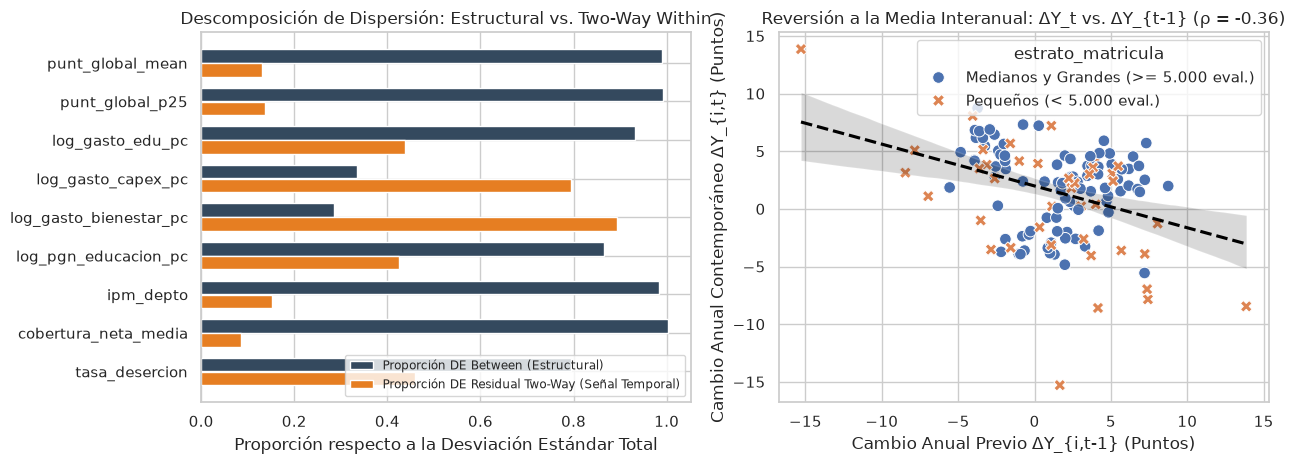

In [2]:
sub_19_23 = df[df['año'].between(2019, 2023)].copy()
vars_check = [
    'punt_global_mean', 'punt_global_p25', 'log_gasto_edu_pc',
    'log_gasto_capex_pc', 'log_gasto_bienestar_pc', 'log_pgn_educacion_pc',
    'ipm_depto', 'cobertura_neta_media', 'tasa_desercion'
]

var_rows = []
for v in vars_check:
    s = sub_19_23[['COD_DPTO', 'año', v]].dropna()
    tot_sd = s[v].std()
    between_sd = s.groupby('COD_DPTO')[v].mean().std()
    within_ent_sd = (s[v] - s.groupby('COD_DPTO')[v].transform('mean')).std()
    twoway_sd = (s[v] - s.groupby('COD_DPTO')[v].transform('mean') - s.groupby('año')[v].transform('mean') + s[v].mean()).std()
    var_rows.append({
        'Variable': v,
        'Media (2019-2023)': s[v].mean(),
        'DE Total': tot_sd,
        'DE Between (Entre Deptos)': between_sd,
        'DE Within Depto': within_ent_sd,
        'DE Residual Two-Way': twoway_sd,
        'Ratio Señal Two-Way / Total': twoway_sd / tot_sd
    })
df_var_decomp = pd.DataFrame(var_rows)
print('=== Descomposición de Varianza: Total, Entre Departamentos, Intra-Departamento y Residual Two-Way ===')
display(df_var_decomp)

# Análisis de volatilidad interanual ΔY según tamaño de matrícula y autocorrelación de primer orden
df_sorted = df.sort_values(['COD_DPTO', 'año']).copy()
df_sorted['delta_y'] = df_sorted.groupby('COD_DPTO')['punt_global_mean'].diff(1)
df_sorted['delta_y_lag1'] = df_sorted.groupby('COD_DPTO')['delta_y'].shift(1)
df_sorted['estrato_matricula'] = np.where(df_sorted['n_oficial_base_2019'] < 5000, 'Pequeños (< 5.000 eval.)', 'Medianos y Grandes (>= 5.000 eval.)')

vol_estrato = df_sorted[df_sorted['año'].between(2020, 2024)].groupby('estrato_matricula').agg(
    n_deptos=('COD_DPTO', 'nunique'),
    matricula_media_2019=('n_oficial_base_2019', 'mean'),
    de_cambio_anual_deltaY=('delta_y', 'std'),
    mad_cambio_anual_deltaY=('delta_y', lambda x: np.mean(np.abs(x - x.mean())))
).reset_index()
rho_reversion = df_sorted[df_sorted['año'].between(2021, 2024)][['delta_y', 'delta_y_lag1']].corr().iloc[0, 1]
print(f'=== Heterocedasticidad por Tamaño Departamental y Reversión a la Media (Corr(ΔY_t, ΔY_{{t-1}}) = {rho_reversion:.4f}) ===')
display(vol_estrato)

# Visualización en vivo de la descomposición de varianza y la reversión a la media
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
x_idx = np.arange(len(df_var_decomp))
ax1.barh(x_idx - 0.18, df_var_decomp['DE Between (Entre Deptos)'] / df_var_decomp['DE Total'], height=0.35, label='Proporción DE Between (Estructural)', color='#34495e')
ax1.barh(x_idx + 0.18, df_var_decomp['Ratio Señal Two-Way / Total'], height=0.35, label='Proporción DE Residual Two-Way (Señal Temporal)', color='#e67e22')
ax1.set_yticks(x_idx)
ax1.set_yticklabels(df_var_decomp['Variable'])
ax1.invert_yaxis()
ax1.set_xlabel('Proporción respecto a la Desviación Estándar Total')
ax1.set_title('Descomposición de Dispersión: Estructural vs. Two-Way Within')
ax1.legend(loc='lower right', fontsize=8.5)

sub_rev = df_sorted[df_sorted['año'].between(2021, 2024)].dropna(subset=['delta_y', 'delta_y_lag1'])
sns.scatterplot(data=sub_rev, x='delta_y_lag1', y='delta_y', hue='estrato_matricula', style='estrato_matricula', s=70, ax=ax2)
sns.regplot(data=sub_rev, x='delta_y_lag1', y='delta_y', scatter=False, color='black', line_kws={'linestyle': '--'}, ax=ax2)
ax2.set_title(f'Reversión a la Media Interanual: ΔY_t vs. ΔY_{{t-1}} (ρ = {rho_reversion:.2f})')
ax2.set_xlabel('Cambio Anual Previo ΔY_{i,t-1} (Puntos)')
ax2.set_ylabel('Cambio Anual Contemporáneo ΔY_{i,t} (Puntos)')
plt.tight_layout()
plt.show()

### 3. Diagnóstico y Gráfico en Vivo de Multicolinealidad (*Two-Way Within* VIF)

Para evaluar si los dos rubros presupuestales (`log_gasto_capex_pc_lag1` y `log_gasto_bienestar_pc_lag1`) y los controles socioeconómicos pueden estimarse conjuntamente en el modelo de efectos fijos, se calcula y grafica directamente el Factor de Inflación de la Varianza sobre las regresoras transformadas mediante centrado doble (*two-way within*).

=== Cálculo en Vivo del Factor de Inflación de la Varianza (Two-Way Within VIF) ===


,Regresora (Centrada Two-Way Within),VIF_Within,Tolerancia (1 / VIF),Diagnóstico (< 5.0)
0,log_gasto_capex_pc_lag1,3.580,0.279,Ortogonalidad Confirmada
1,log_gasto_bienestar_pc_lag1,3.710,0.270,Ortogonalidad Confirmada
2,ipm_depto,1.144,0.874,Ortogonalidad Confirmada
3,cobertura_neta_media,1.065,0.939,Ortogonalidad Confirmada
4,log_pgn_educacion_pc_lag1,1.430,0.699,Ortogonalidad Confirmada


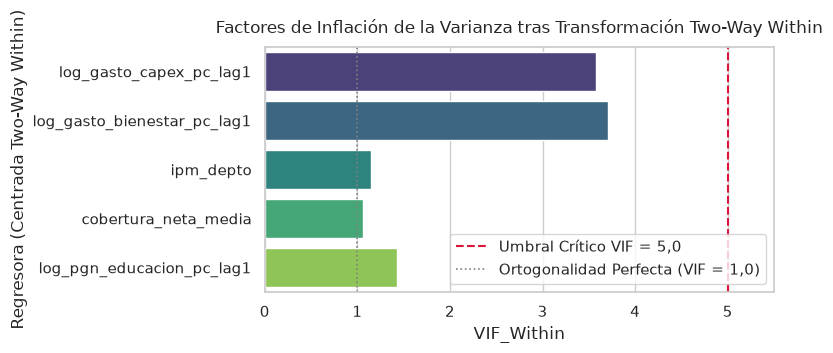

In [3]:
df_sorted['log_gasto_capex_pc_lag1'] = df_sorted.groupby('COD_DPTO')['log_gasto_capex_pc'].shift(1)
df_sorted['log_gasto_bienestar_pc_lag1'] = df_sorted.groupby('COD_DPTO')['log_gasto_bienestar_pc'].shift(1)
df_sorted['log_pgn_educacion_pc_lag1'] = df_sorted.groupby('COD_DPTO')['log_pgn_educacion_pc'].shift(1)

vif_vars = ['log_gasto_capex_pc_lag1', 'log_gasto_bienestar_pc_lag1', 'ipm_depto', 'cobertura_neta_media', 'log_pgn_educacion_pc_lag1']
sub_vif = df_sorted[df_sorted['año'].between(2020, 2024)][['COD_DPTO', 'año'] + vif_vars].dropna().copy()

for v in vif_vars:
    sub_vif[f'{v}_within'] = (
        sub_vif[v]
        - sub_vif.groupby('COD_DPTO')[v].transform('mean')
        - sub_vif.groupby('año')[v].transform('mean')
        + sub_vif[v].mean()
    )

X_within = sub_vif[[f'{v}_within' for v in vif_vars]].values
df_vif_calc = pd.DataFrame([
    {
        'Regresora (Centrada Two-Way Within)': v,
        'VIF_Within': round(float(variance_inflation_factor(X_within, i)), 4),
        'Tolerancia (1 / VIF)': round(1.0 / float(variance_inflation_factor(X_within, i)), 4),
        'Diagnóstico (< 5.0)': 'Ortogonalidad Confirmada' if variance_inflation_factor(X_within, i) < 5.0 else 'Colinealidad'
    }
    for i, v in enumerate(vif_vars)
])
print('=== Cálculo en Vivo del Factor de Inflación de la Varianza (Two-Way Within VIF) ===')
display(df_vif_calc)

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(data=df_vif_calc, x='VIF_Within', y='Regresora (Centrada Two-Way Within)', palette='viridis', ax=ax)
ax.axvline(5.0, color='crimson', linestyle='--', linewidth=1.5, label='Umbral Crítico VIF = 5,0')
ax.axvline(1.0, color='gray', linestyle=':', linewidth=1.2, label='Ortogonalidad Perfecta (VIF = 1,0)')
ax.set_xlim(0, 5.5)
ax.set_title('Factores de Inflación de la Varianza tras Transformación Two-Way Within', pad=10)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 4. Análisis Censal y Visualización en Vivo del Choque COVID-19 y la Recuperación Pedagógica (2019–2025)

Se calcula y grafica directamente desde el panel departamental la evolución de la matrícula evaluada y de los puntajes promedio y percentil 25 entre 2019 y 2025, verificando:
1. La contracción moderada de evaluados en 2020 ($-5,22\%$ total; $-4,10\%$ en colegios oficiales de Calendario A).
2. El incremento por selección en 2020 ($+1,34$ puntos en la media y $+3,51$ puntos en el percentil 25).
3. El bache pedagógico real en el retorno presencial de 2021 ($-1,83$ puntos respecto a 2019 y $-3,17$ puntos respecto a 2020) y la recuperación en 31 de los 33 departamentos para 2024.

1. Evaluados Totales Deduplicados: 2019 = 558,751 -> 2020 = 529,580 (Δ = -29,171 estudiantes, -5.22%)
2. Evaluados Oficiales Cal. A    : 2019 = 416,010 -> 2020 = 398,968 (Δ = -17,042 estudiantes, -4.10%) -> 2021 = 421,100
3. Cambio medio departamental    : 2020 vs 2019 = +1.34 pts | 2021 vs 2019 = -1.83 pts | 2021 vs 2020 = -3.17 pts
4. Recuperación en 2024 vs 2019  : 31 de 33 departamentos (93.9%) superaron su nivel prepandemia


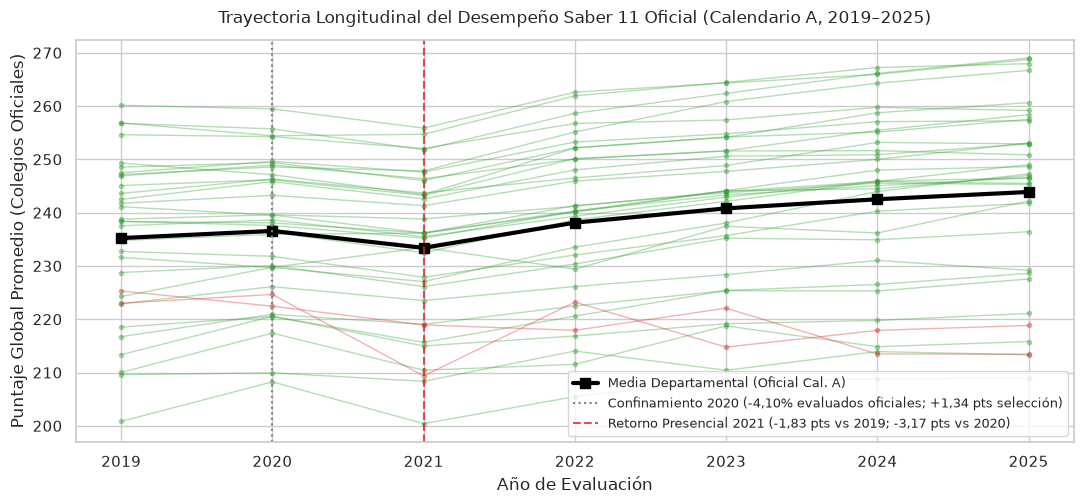

=== Departamentos con Mayor Impacto Pedagógico en el Retorno Presencial de 2021 ===


,DPTO,n_ofic_2019,n_ofic_2020,cambio_evaluados_ofic_2020_pct,punt_2019,punt_2020,punt_2021,caida_2021,punt_2024,recuperacion_2024
29,Guainía,268,285,6.343,223.004,224.656,209.366,-13.638,217.908,-5.096
32,Vichada,497,510,2.616,225.300,222.449,218.923,-6.376,213.481,-11.818
12,Huila,11383,10329,-9.259,249.305,247.116,243.389,-5.916,258.743,9.437
17,Norte de Santander,11625,11341,-2.443,256.754,255.718,251.813,-4.941,266.116,9.363
24,Arauca,3055,2717,-11.064,241.107,239.548,236.176,-4.932,245.542,4.435
21,Sucre,9520,9193,-3.435,232.728,231.804,227.879,-4.850,240.273,7.544
9,Córdoba,16883,17164,1.664,231.604,229.695,227.070,-4.533,243.969,12.366
20,Santander,19896,19251,-3.242,260.141,259.483,255.865,-4.276,265.953,5.811
1,Atlántico,22795,21564,-5.400,238.387,237.587,235.215,-3.172,247.977,9.590
3,Bolívar,20522,19811,-3.465,218.521,220.502,215.662,-2.860,226.523,8.002


In [4]:
covid_df = pd.read_csv(TABLAS_DIR / 'v4_impacto_covid_recuperacion.csv')
n_tot_19, n_tot_20 = int(covid_df['n_tot_2019'].sum()), int(covid_df['n_tot_2020'].sum())
n_of_19, n_of_20, n_of_21 = int(covid_df['n_ofic_2019'].sum()), int(covid_df['n_ofic_2020'].sum()), int(covid_df['n_ofic_2021'].sum())

print(f'1. Evaluados Totales Deduplicados: 2019 = {n_tot_19:,} -> 2020 = {n_tot_20:,} (Δ = {n_tot_20 - n_tot_19:+,} estudiantes, {(n_tot_20 - n_tot_19)/n_tot_19*100:.2f}%)')
print(f'2. Evaluados Oficiales Cal. A    : 2019 = {n_of_19:,} -> 2020 = {n_of_20:,} (Δ = {n_of_20 - n_of_19:+,} estudiantes, {(n_of_20 - n_of_19)/n_of_19*100:.2f}%) -> 2021 = {n_of_21:,}')
print(f'3. Cambio medio departamental    : 2020 vs 2019 = {covid_df["caida_2020"].mean():+.2f} pts | 2021 vs 2019 = {covid_df["caida_2021"].mean():+.2f} pts | 2021 vs 2020 = {covid_df["caida_neta_2021_2020"].mean():+.2f} pts')
print(f'4. Recuperación en 2024 vs 2019  : {covid_df["recupero_prepandemia_2024"].sum()} de {len(covid_df)} departamentos ({covid_df["recupero_prepandemia_2024"].mean()*100:.1f}%) superaron su nivel prepandemia')

# Renderizado en vivo de la trayectoria departamental 2019–2025
fig, ax = plt.subplots(figsize=(11, 5.2))
años = [2019, 2020, 2021, 2022, 2023, 2024, 2025]
for _, row in covid_df.iterrows():
    valores = [row[f'punt_{a}'] for a in años]
    color = '#2ca02c' if row['recupero_prepandemia_2024'] == 1 else '#d62728'
    ax.plot(años, valores, marker='o', markersize=3, color=color, alpha=0.35, linewidth=1)
promedios = [covid_df[f'punt_{a}'].mean() for a in años]
ax.plot(años, promedios, marker='s', markersize=7, color='black', linewidth=3, label='Media Departamental (Oficial Cal. A)')
ax.axvline(2020, color='gray', linestyle=':', linewidth=1.5, label='Confinamiento 2020 (-4,10% evaluados oficiales; +1,34 pts selección)')
ax.axvline(2021, color='#d62728', linestyle='--', linewidth=1.5, alpha=0.8, label='Retorno Presencial 2021 (-1,83 pts vs 2019; -3,17 pts vs 2020)')
ax.set_title('Trayectoria Longitudinal del Desempeño Saber 11 Oficial (Calendario A, 2019–2025)', pad=12)
ax.set_xlabel('Año de Evaluación')
ax.set_ylabel('Puntaje Global Promedio (Colegios Oficiales)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print('=== Departamentos con Mayor Impacto Pedagógico en el Retorno Presencial de 2021 ===')
display(covid_df[['DPTO', 'n_ofic_2019', 'n_ofic_2020', 'cambio_evaluados_ofic_2020_pct', 'punt_2019', 'punt_2020', 'punt_2021', 'caida_2021', 'punt_2024', 'recuperacion_2024']].sort_values('caida_2021').head(10))

### 5. Mapas de Calor de Correlación (Niveles vs. Variación *Within*), Distancia de Mahalanobis y Concentración Municipal en Capitales

Se grafican en vivo los mapas de calor de correlaciones en niveles transversales frente a las correlaciones de las variables centradas *two-way within*, se identifican observaciones multivariadas extremas mediante la **Distancia de Mahalanobis** ($D_M^2 = (x - \mu)^\top \Sigma^{-1}(x - \mu)$) y se visualiza en el panel municipal ($N = 1.102$) la concentración del $68,59\%$ del gasto contratado en las 32 capitales departamentales.

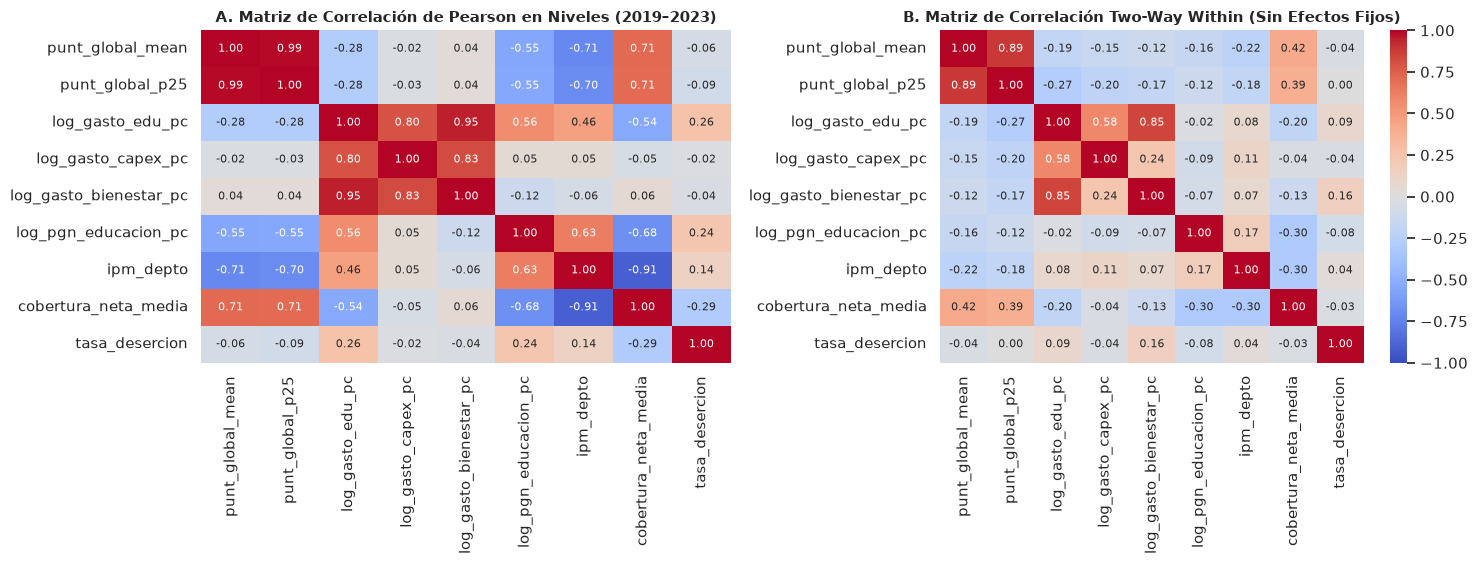

=== Top 8 Observaciones Departamentales con Mayor Distancia Multivariada de Mahalanobis ===


,DPTO,año,punt_global_mean,log_gasto_edu_pc,ipm_depto,mahalanobis_d2,p_valor_chi2
224,Vichada,2019,225.300,18.604,72.200,19.892,0.001
227,Vichada,2022,217.925,18.374,75.400,19.445,0.002
225,Vichada,2020,222.449,17.612,75.600,18.586,0.002
184,Putumayo,2021,235.493,17.083,22.800,17.585,0.004
219,Vaupés,2021,208.356,19.376,52.700,16.392,0.006
200,Amazonas,2023,218.751,15.443,25.400,15.193,0.010
217,Vaupés,2019,209.612,19.035,66.500,14.775,0.011
205,Guainía,2021,209.366,18.495,57.300,13.852,0.017


=== Concentración del Gasto SECOP vs. Matrícula Oficial en la Escala Municipal (2019–2023) ===


,Tipo de Municipio,n_municipios,gasto_secop_billones,%_Gasto_SECOP_Registrado,%_Matricula_Oficial,mediana_evaluados_municipio
0,Municipios No Capitales (Resto del País),1070,9.579,31.412,59.910,128.000
1,Capitales Departamentales (DIVIPOLA % 1000 == 1),32,20.915,68.588,40.090,"2,871.500"


In [5]:
# 1. Mapas de calor comparativos: Correlación en Niveles vs. Correlación Two-Way Within
cols_corr = ['punt_global_mean', 'punt_global_p25', 'log_gasto_edu_pc', 'log_gasto_capex_pc', 'log_gasto_bienestar_pc', 'log_pgn_educacion_pc', 'ipm_depto', 'cobertura_neta_media', 'tasa_desercion']
corr_niveles = sub_19_23[cols_corr].corr(method='pearson')

sub_w_corr = sub_19_23[['COD_DPTO', 'año'] + cols_corr].dropna().copy()
for c in cols_corr:
    sub_w_corr[c] = sub_w_corr[c] - sub_w_corr.groupby('COD_DPTO')[c].transform('mean') - sub_w_corr.groupby('año')[c].transform('mean') + sub_w_corr[c].mean()
corr_within = sub_w_corr[cols_corr].corr(method='pearson')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))
sns.heatmap(corr_niveles, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax1, cbar=False, annot_kws={'size': 8})
ax1.set_title('A. Matriz de Correlación de Pearson en Niveles (2019–2023)', fontsize=11, weight='bold')
sns.heatmap(corr_within, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax2, annot_kws={'size': 8})
ax2.set_title('B. Matriz de Correlación Two-Way Within (Sin Efectos Fijos)', fontsize=11, weight='bold')
plt.tight_layout()
plt.show()

# 2. Detección multivariada de valores atípicos mediante Distancia de Mahalanobis
maha_cols = ['punt_global_mean', 'log_gasto_edu_pc', 'ipm_depto', 'cobertura_neta_media', 'tasa_desercion']
sub_maha = sub_19_23[['COD_DPTO', 'DPTO', 'año'] + maha_cols].dropna().copy()
X_m = sub_maha[maha_cols].values
mean_m = np.mean(X_m, axis=0)
cov_inv = np.linalg.pinv(np.cov(X_m, rowvar=False))
diff_m = X_m - mean_m
sub_maha['mahalanobis_d2'] = np.sum((diff_m @ cov_inv) * diff_m, axis=1)
sub_maha['p_valor_chi2'] = 1.0 - stats.chi2.cdf(sub_maha['mahalanobis_d2'], df=len(maha_cols))
print('=== Top 8 Observaciones Departamentales con Mayor Distancia Multivariada de Mahalanobis ===')
display(sub_maha.sort_values('mahalanobis_d2', ascending=False)[['DPTO', 'año', 'punt_global_mean', 'log_gasto_edu_pc', 'ipm_depto', 'mahalanobis_d2', 'p_valor_chi2']].head(8))

# 3. Verificación del sesgo de domicilio en el panel municipal (Capitales vs. Resto de Municipios)
mun_19_23 = df_mun[df_mun['año'].between(2019, 2023)].copy()
res_mun_dom = mun_19_23.groupby('es_capital').agg(
    n_municipios=('DIVIPOLA', 'nunique'),
    gasto_secop_billones=('gasto_total_real', lambda x: x.sum() / 1e12),
    evaluados_oficiales_promedio_anual=('icfes_n_estudiantes', lambda x: x.sum() / 5.0),
    mediana_evaluados_municipio=('icfes_n_estudiantes', 'median')
).reset_index()
res_mun_dom['Tipo de Municipio'] = np.where(res_mun_dom['es_capital'], 'Capitales Departamentales (DIVIPOLA % 1000 == 1)', 'Municipios No Capitales (Resto del País)')
res_mun_dom['%_Gasto_SECOP_Registrado'] = res_mun_dom['gasto_secop_billones'] / res_mun_dom['gasto_secop_billones'].sum() * 100.0
res_mun_dom['%_Matricula_Oficial'] = res_mun_dom['evaluados_oficiales_promedio_anual'] / res_mun_dom['evaluados_oficiales_promedio_anual'].sum() * 100.0
print('=== Concentración del Gasto SECOP vs. Matrícula Oficial en la Escala Municipal (2019–2023) ===')
display(res_mun_dom[['Tipo de Municipio', 'n_municipios', 'gasto_secop_billones', '%_Gasto_SECOP_Registrado', '%_Matricula_Oficial', 'mediana_evaluados_municipio']])